In [ ]:
# En Google Colab, carga los dos CSV limpios cuando aparezca el selector.
# En Jupyter local, deja ambos archivos en la misma carpeta del notebook.
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Entorno local: asegúrate de que los dos CSV estén junto al notebook.")


Saving IRA_La_Libertad_2015_2024.csv to IRA_La_Libertad_2015_2024 (1).csv
Saving malaria_limpio.csv to malaria_limpio (1).csv


In [ ]:
# Colab ya incluye normalmente estas bibliotecas. Si falta alguna, ejecuta:
# %pip install pandas numpy matplotlib scikit-learn

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

OUT = Path("graficos_punto4_1")
OUT.mkdir(exist_ok=True)
IRA_FILE = Path("IRA_La_Libertad_2015_2024_corregido.csv")
MALARIA_FILE = Path("malaria_limpio_download.csv")
IRA_COLS = ["IRA_menores_2_meses", "IRA_2_a_11_meses", "IRA_1_a_4_anos"]

plt.style.use("seaborn-v0_8-whitegrid")


# 1. Preparar IRA
Se filtra el código oficial del departamento (13), se suman los tres grupos de edad de IRA y se excluyen las columnas de neumonía del objetivo.

In [ ]:
# Corregir rutas según los archivos realmente disponibles
import os
if os.path.exists("IRA_La_Libertad_2015_2024.csv"):
    IRA_FILE = Path("IRA_La_Libertad_2015_2024.csv")
if os.path.exists("malaria_limpio.csv"):
    MALARIA_FILE = Path("malaria_limpio.csv")

df = pd.read_csv(IRA_FILE, sep=";", dtype={"Codigo_Ubigeo": str}, encoding="utf-8-sig")
df["Codigo_Departamento"] = pd.to_numeric(df["Codigo_Departamento"], errors="coerce")
for col in IRA_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
df["Ano"] = pd.to_numeric(df["Ano"], errors="coerce")
df["Semana_Epidemiologica"] = pd.to_numeric(df["Semana_Epidemiologica"], errors="coerce")
df = df.loc[df["Codigo_Departamento"].eq(13)].copy()
df["Total_IRA"] = df[IRA_COLS].sum(axis=1)
df["Ano"] = df["Ano"].astype(int)
df["Semana_Epidemiologica"] = df["Semana_Epidemiologica"].astype(int)

print(f"Filas de IRA analizadas: {len(df):,}")
print(f"Años: {df['Ano'].min()}–{df['Ano'].max()}; 2024 llega hasta SE {df.loc[df.Ano.eq(2024), 'Semana_Epidemiologica'].max()}.")

Filas de IRA analizadas: 36,804
Años: 2015–2024; 2024 llega hasta SE 26.


# **Figuras 1–3: IRA**

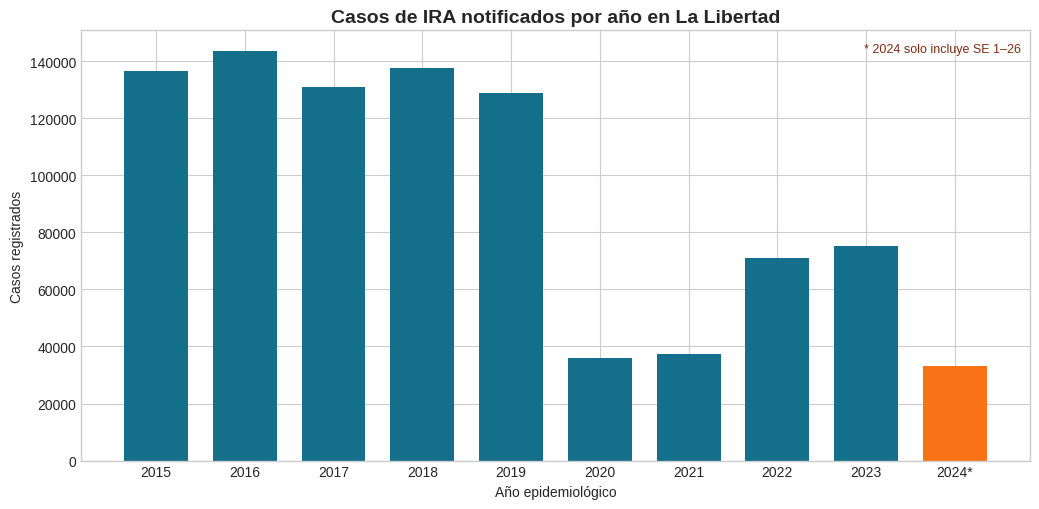

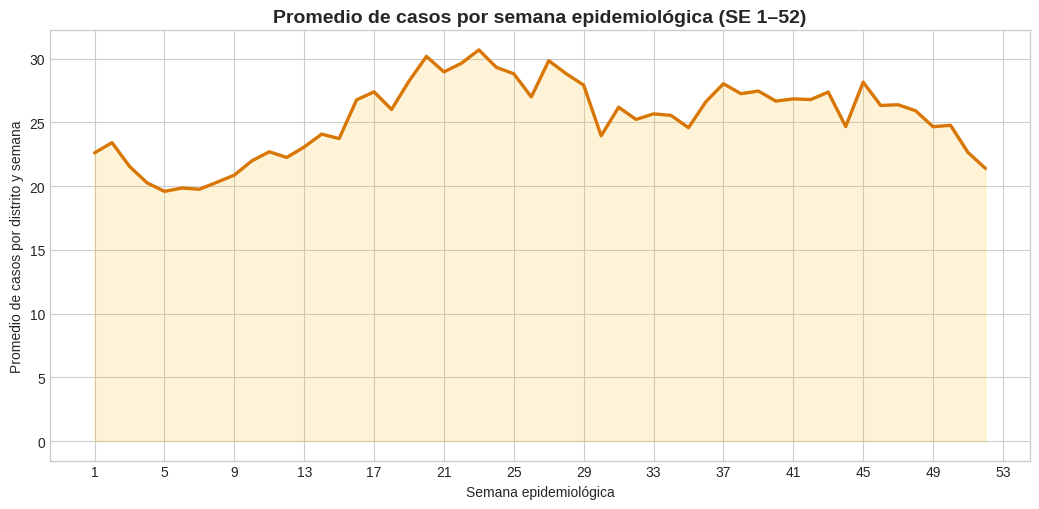

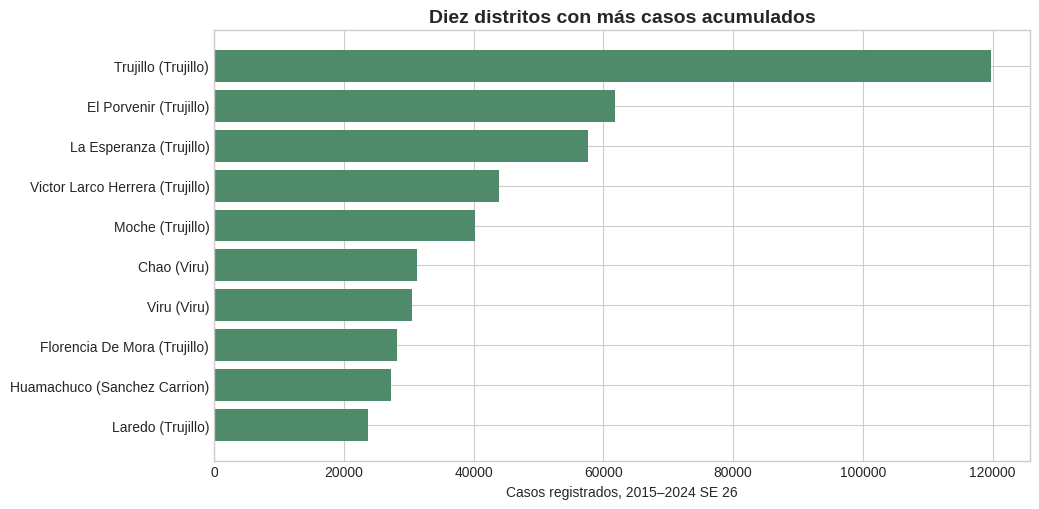

In [ ]:
# Figura 1 — casos anuales
annual = df.groupby("Ano", as_index=False)["Total_IRA"].sum()
fig, ax = plt.subplots(figsize=(10.5, 5.2))
bar_colors = ["#136F8A" if year < 2024 else "#F97316" for year in annual["Ano"]]
ax.bar(annual["Ano"], annual["Total_IRA"], color=bar_colors, width=0.72)
ax.set_title("Casos de IRA notificados por año en La Libertad", fontsize=14, weight="bold")
ax.text(0.99, 0.97, "* 2024 solo incluye SE 1–26", transform=ax.transAxes, ha="right", va="top", fontsize=9, color="#7C2D12")
ax.set_xlabel("Año epidemiológico"); ax.set_ylabel("Casos registrados")
ax.ticklabel_format(axis="y", style="plain")
ax.set_xticks(annual["Ano"]); ax.set_xticklabels([str(y) + ("*" if y == 2024 else "") for y in annual["Ano"]])
fig.tight_layout(); fig.savefig(OUT / "figura_1_serie_anual_ira.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

# Figura 2 — promedio por semana epidemiológica
season = (df.loc[df["Semana_Epidemiologica"].le(52)]
          .groupby("Semana_Epidemiologica", as_index=False)["Total_IRA"].mean())
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.plot(season["Semana_Epidemiologica"], season["Total_IRA"], color="#D97706", linewidth=2.4)
ax.fill_between(season["Semana_Epidemiologica"], season["Total_IRA"], color="#FBBF24", alpha=0.18)
ax.set_title("Promedio de casos por semana epidemiológica (SE 1–52)", fontsize=14, weight="bold")
ax.set_xlabel("Semana epidemiológica"); ax.set_ylabel("Promedio de casos por distrito y semana")
ax.set_xticks(range(1, 54, 4)); fig.tight_layout()
fig.savefig(OUT / "figura_2_estacionalidad_ira.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

# Figura 3 — diez distritos con más casos acumulados
top_districts = (df.groupby(["Codigo_Ubigeo", "Provincia", "Distrito"], as_index=False)["Total_IRA"]
                 .sum().sort_values("Total_IRA", ascending=False).head(10))
labels = top_districts["Distrito"].str.title() + " (" + top_districts["Provincia"].str.title() + ")"
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.barh(labels.iloc[::-1], top_districts["Total_IRA"].iloc[::-1], color="#4F8A6B")
ax.set_title("Diez distritos con más casos acumulados", fontsize=14, weight="bold")
ax.set_xlabel("Casos registrados, 2015–2024 SE 26"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(OUT / "figura_3_distritos_ira.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)


# Figura 4: IRA observado frente a predicho
Se conserva la separación temporal del análisis: entrenamiento 2015–2021, validación 2022 y prueba 2023–2024 (hasta SE 26). El modelo se elige por MAE en 2022.

Modelo elegido por MAE de validación: Random Forest
MAE 2022 por modelo: {'Random Forest': 6.823, 'Extra Trees': 6.839}


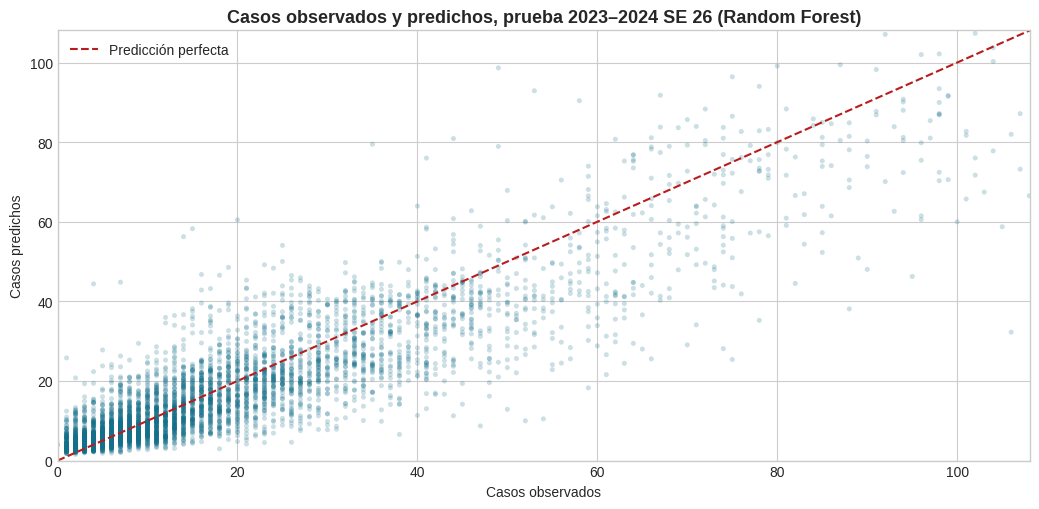

In [ ]:
# Crear variables históricas por distrito y semana
base = df[["Codigo_Ubigeo", "Provincia", "Distrito", "Ano", "Semana_Epidemiologica", "Total_IRA"]].copy()
year_lengths = df.groupby("Ano")["Semana_Epidemiologica"].max().astype(int).to_dict()
year_offsets = {}; offset = 0
for year in sorted(year_lengths):
    year_offsets[int(year)] = offset
    offset += year_lengths[year]
base["week_idx"] = [year_offsets[int(y)] + int(w) - 1 for y, w in zip(base["Ano"], base["Semana_Epidemiologica"])]
for lag in (1, 2, 3, 4):
    prior = base[["Codigo_Ubigeo", "week_idx", "Total_IRA"]].copy()
    prior["week_idx"] += lag
    prior = prior.rename(columns={"Total_IRA": f"lag_{lag}"})
    base = base.merge(prior, on=["Codigo_Ubigeo", "week_idx"], how="left", validate="one_to_one")
prior_year = base[["Codigo_Ubigeo", "Ano", "Semana_Epidemiologica", "Total_IRA"]].copy()
prior_year["Ano"] += 1
prior_year = prior_year.rename(columns={"Total_IRA": "lag_52"})
base = base.merge(prior_year, on=["Codigo_Ubigeo", "Ano", "Semana_Epidemiologica"], how="left", validate="one_to_one")
base["media_movil_4"] = base[["lag_1", "lag_2", "lag_3", "lag_4"]].mean(axis=1)
base["semana_sin"] = np.sin(2 * np.pi * base["Semana_Epidemiologica"] / 52.18)
base["semana_cos"] = np.cos(2 * np.pi * base["Semana_Epidemiologica"] / 52.18)
feature_cols = ["lag_1", "lag_2", "lag_3", "lag_4", "lag_52", "media_movil_4", "semana_sin", "semana_cos", "Ano", "Codigo_Ubigeo"]
model_data = base.dropna(subset=[f"lag_{n}" for n in (1, 2, 3, 4, 52)]).copy()
train = model_data.loc[model_data["Ano"].le(2021)]
validation = model_data.loc[model_data["Ano"].eq(2022)]
train_val = model_data.loc[model_data["Ano"].le(2022)]
test = model_data.loc[model_data["Ano"].ge(2023)]
numeric = ["lag_1", "lag_2", "lag_3", "lag_4", "lag_52", "media_movil_4", "semana_sin", "semana_cos", "Ano"]
categorical = ["Codigo_Ubigeo"]

def make_pipeline(estimator):
    pre = ColumnTransformer([("numeric", "passthrough", numeric),
                             ("district", OneHotEncoder(handle_unknown="ignore"), categorical)], remainder="drop")
    reg = Pipeline([("features", pre), ("model", estimator)])
    return TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)

models = {
    "Random Forest": RandomForestRegressor(n_estimators=160, max_depth=16, min_samples_leaf=4, max_features=0.8, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=160, max_depth=16, min_samples_leaf=4, max_features=0.8, random_state=42, n_jobs=-1),
}
validation_mae = {}
for name, estimator in models.items():
    model = make_pipeline(estimator)
    model.fit(train[feature_cols], train["Total_IRA"])
    p = np.maximum(0, model.predict(validation[feature_cols]))
    validation_mae[name] = mean_absolute_error(validation["Total_IRA"], p)
selected = min(validation_mae, key=validation_mae.get)
final_model = make_pipeline(models[selected])
final_model.fit(train_val[feature_cols], train_val["Total_IRA"])
pred = np.maximum(0, final_model.predict(test[feature_cols]))
test_y = test["Total_IRA"].to_numpy()
print("Modelo elegido por MAE de validación:", selected)
print("MAE 2022 por modelo:", {k: round(v, 3) for k, v in validation_mae.items()})

fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.scatter(test_y, pred, alpha=0.22, s=13, color="#136F8A", edgecolors="none")
lim = max(float(np.quantile(test_y, 0.99)), float(np.quantile(pred, 0.99)))
ax.plot([0, lim], [0, lim], linestyle="--", color="#B91C1C", linewidth=1.5, label="Predicción perfecta")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f"Casos observados y predichos, prueba 2023–2024 SE 26 ({selected})", fontsize=13, weight="bold")
ax.set_xlabel("Casos observados"); ax.set_ylabel("Casos predichos"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "figura_4_observado_predicho.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)


# 2. Preparar malaria y generar figuras 7–9
El CSV limpio de malaria debe conservar las columnas departamento, ubigeo, provincia, distrito, ano, semana y enfermedad. Cada fila se trata como un caso notificado, igual que en el análisis original.

In [ ]:
# Corregir ruta del archivo de malaria según el archivo subido en el entorno
import os
if os.path.exists("malaria_limpio.csv"):
    MALARIA_FILE = Path("malaria_limpio.csv")

mal = pd.read_csv(MALARIA_FILE, low_memory=False, dtype={"ubigeo": str}, encoding="utf-8-sig")
ll = mal.loc[mal["departamento"].astype(str).str.strip().str.upper().eq("LA LIBERTAD")].copy()
ll["ano"] = pd.to_numeric(ll["ano"], errors="coerce")
ll["semana"] = pd.to_numeric(ll["semana"], errors="coerce")
ll["ubigeo"] = ll["ubigeo"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.zfill(6)
ll = ll.loc[ll["ano"].notna() & ll["semana"].between(1, 53)].copy()
ll["ano"] = ll["ano"].astype(int); ll["semana"] = ll["semana"].astype(int)
print(f"Casos de malaria de La Libertad: {len(ll):,}; años {ll.ano.min()}–{ll.ano.max()}.")

Casos de malaria de La Libertad: 1,362; años 2009–2022.


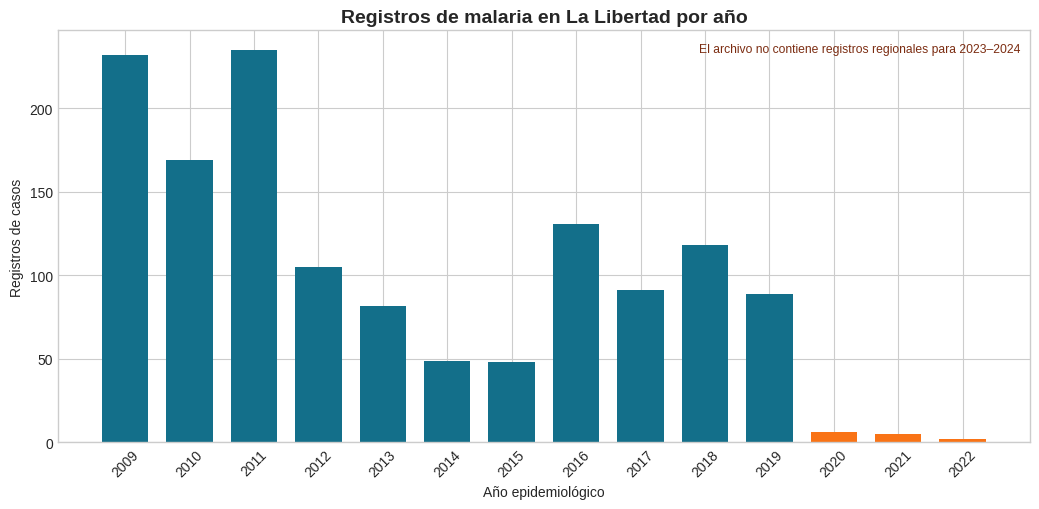

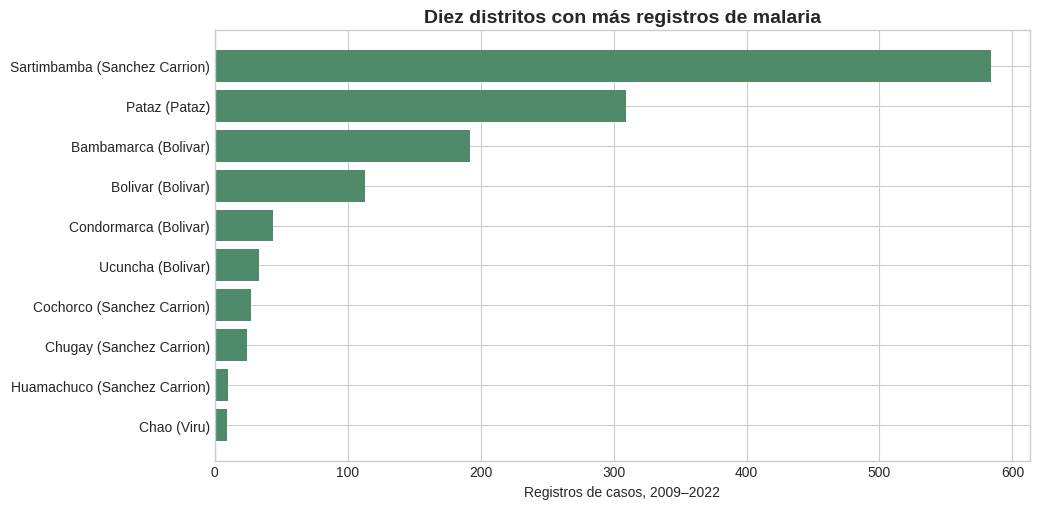

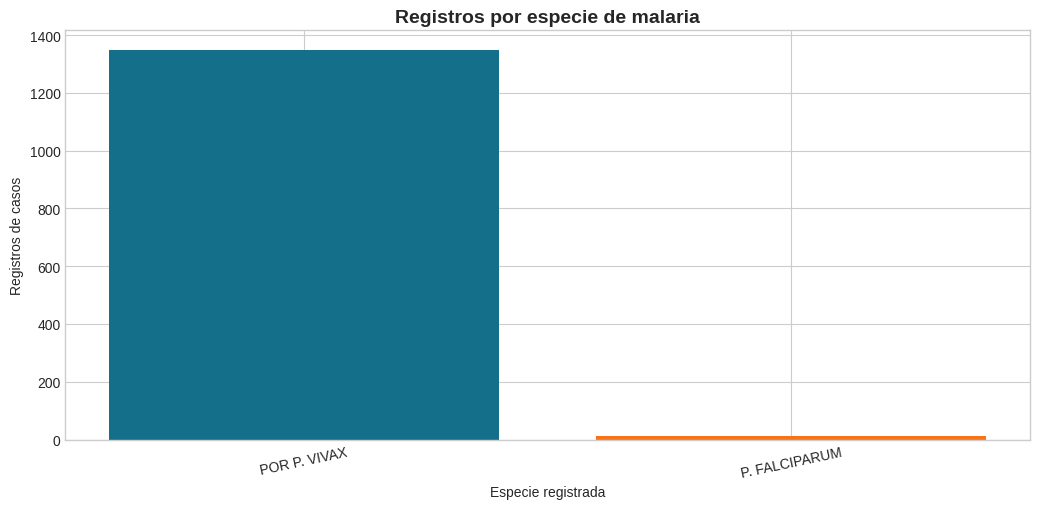

In [ ]:
# Figura 7 — registros anuales de malaria
annual_mal = ll.groupby("ano").size().rename("casos").reset_index()
years = pd.DataFrame({"ano": range(int(ll.ano.min()), int(ll.ano.max()) + 1)})
annual_mal = years.merge(annual_mal, on="ano", how="left").fillna({"casos": 0})
annual_mal["casos"] = annual_mal["casos"].astype(int)
fig, ax = plt.subplots(figsize=(10.5, 5.2))
bar_colors = ["#136F8A" if y <= 2019 else "#F97316" for y in annual_mal["ano"]]
ax.bar(annual_mal["ano"], annual_mal["casos"], color=bar_colors, width=0.72)
ax.set_title("Registros de malaria en La Libertad por año", fontsize=14, weight="bold")
ax.set_xlabel("Año epidemiológico"); ax.set_ylabel("Registros de casos")
ax.set_xticks(annual_mal["ano"]); ax.tick_params(axis="x", rotation=45)
ax.text(0.99, 0.97, "El archivo no contiene registros regionales para 2023–2024", transform=ax.transAxes, ha="right", va="top", fontsize=8.7, color="#7C2D12")
fig.tight_layout(); fig.savefig(OUT / "figura_7_malaria_anual.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

# Figura 8 — diez distritos con más registros
top_mal = (ll.groupby(["ubigeo", "provincia", "distrito"]).size().rename("casos")
           .reset_index().sort_values("casos", ascending=False).head(10))
labels = top_mal["distrito"].str.title() + " (" + top_mal["provincia"].str.title() + ")"
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.barh(labels.iloc[::-1], top_mal["casos"].iloc[::-1], color="#4F8A6B")
ax.set_title("Diez distritos con más registros de malaria", fontsize=14, weight="bold")
ax.set_xlabel("Registros de casos, 2009–2022"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(OUT / "figura_8_malaria_distritos.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

# Figura 9 — registros por especie
species = ll["enfermedad"].value_counts().rename_axis("enfermedad").reset_index(name="casos")
fig, ax = plt.subplots(figsize=(10.5, 5.2))
labels = species["enfermedad"].str.replace("MALARIA", "", regex=False).str.strip()
ax.bar(labels, species["casos"], color=["#136F8A", "#F97316"][:len(species)])
ax.set_title("Registros por especie de malaria", fontsize=14, weight="bold")
ax.set_xlabel("Especie registrada"); ax.set_ylabel("Registros de casos")
ax.tick_params(axis="x", rotation=12)
fig.tight_layout(); fig.savefig(OUT / "figura_9_malaria_especie.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)
